# Face-recognition attendance on ChokePoint

This notebook evaluates a face-recognition attendance system on the ChokePoint
dataset with `infer-ci`, from start to end:

1. Download the ground truth.
2. Load who really passed (the truth).
3. Load the face predictions and turn them into attendance records.
4. Compare the records with the truth.
5. Compute the metrics with 95% confidence intervals.
6. Check how the results change with the settings.

The notebook shows only tables and charts of metrics, no images of people.
See `README.md` in this folder for what to install and download.

## Setup

Run the notebook from `notebooks/chokepoint/`. The data goes to `datasets/chokepoint/`
at the repository root, which is not committed.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))

from notebooks.chokepoint.attendance_metrics import (
    UNENROLLED, attendance_metrics, compare, count_results, records_from_predictions)
from notebooks.chokepoint.chokepoint_data import download_chokepoint, load_ground_truth

DATA = ROOT / "datasets" / "chokepoint"
PREDICTIONS = DATA / "predictions" / "P2E_S1_C3.csv"

# Chosen setting (see the sweep at the end)
THRESHOLD, K, TOLERANCE = 0.5, 6, 1.0

## 1. Download the ground truth

`groundtruth.tar.xz` is 0.5 MB. It is downloaded and extracted only once;
a second run skips both steps.

In [2]:
download_chokepoint("groundtruth.tar.xz", dest=DATA)
sorted(p.name for p in (DATA / "groundtruth").glob("*.xml"))[:3]

['P1E_S1_C1.xml', 'P1E_S1_C2.xml', 'P1E_S1_C3.xml']

## 2. Load the truth

`load_ground_truth` returns three tables. We use `attendance`: one row per person,
session and camera, with the time of the first frame where the person is seen
(`start_time_s`, frame / 30).

The 4 people who were never enrolled (0002, 0028, 0029, 0030) stay in the table,
but they are not counted in the metrics: the system cannot recognise them, so
not recording them is correct.

In [3]:
frames, passes, attendance = load_ground_truth(DATA / "groundtruth")
pd.DataFrame({
    "rows": [len(attendance)],
    "sessions": [attendance["session"].nunique()],
    "people": [attendance["person_id"].nunique()],
    "unenrolled people": [len(set(UNENROLLED) & set(attendance["person_id"]))],
})

,rows,sessions,people,unenrolled people
0,1281,24,29,4


## 3. Predictions and attendance records

The predictions come from `predict_insightface.py` (INF-49): one row per detected face.
Read `best_id` as text to keep IDs such as `0014`.

A person is recorded with these rules:

- in each frame, only the largest face is used (the person walking through);
- the face is recognised as person P when `best_id` = P and `best_score` ≥ threshold;
- the person is recorded at the time of the k-th recognised frame.

In [4]:
predictions = pd.read_csv(PREDICTIONS, dtype={"best_id": str})
records = records_from_predictions(predictions, threshold=THRESHOLD, k=K)

# Compare only with the truth of the sessions and cameras in the predictions
truth = attendance.merge(predictions[["session", "camera"]].drop_duplicates())
pd.DataFrame({
    "faces": [len(predictions)],
    "frames": [predictions.groupby(["session", "camera"])["frame"].nunique().sum()],
    "records": [len(records)],
    "truth rows (enrolled)": [(~truth["person_id"].isin(UNENROLLED)).sum()],
})

,faces,frames,records,truth rows (enrolled)
0,2247,1956,25,25


## 4. Compare the records with the truth

Each record is compared with the truth of the same session and camera:

- **match**: the person passed and |record time − start time| ≤ tolerance
- **late / early**: the person passed, but the time difference is larger than the tolerance
- **missed**: the person passed but was not recorded
- **extra**: the person was recorded but did not pass

In [5]:
outcomes = compare(records, truth, tolerance=TOLERANCE)
counts = pd.DataFrame([{"session": s, **count_results(g)} for s, g in outcomes.groupby("session")])
counts.loc[len(counts)] = {"session": "all", **count_results(outcomes)}
counts

,session,match,late,early,missed,extra
0,P2E_S1.1,21,0,0,0,0
1,P2E_S1.2,4,0,0,0,0
2,all,25,0,0,0,0


## 5. Metrics with 95% confidence intervals

- Accuracy = match / (match + late + early + missed + extra), and the late/early,
  missed and extra rates, with Wilson intervals.
- Event precision, recall and F1 (`average="binary"`): a late or early record is
  one missed pass (FN) and one wrong record (FP).
- Timing for match and late/early records, in seconds: MAE, mean bias
  (record time − start time) and the 95th percentile of |difference|, with bootstrap intervals.

In [6]:
results = pd.concat(
    [attendance_metrics(outcomes, group="all")]
    + [attendance_metrics(g, group=s) for s, g in outcomes.groupby("session")],
    ignore_index=True,
)
results.round(3)

,group,metric,value,lower,upper
0,all,Accuracy,1.000,0.867,1.000
1,all,Late/early rate,0.000,0.000,0.133
2,all,Missed rate,0.000,0.000,0.133
3,all,Extra rate,0.000,0.000,0.133
4,all,Precision,1.000,0.867,1.000
5,all,Recall,1.000,0.867,1.000
6,all,F1,1.000,1.000,1.000
7,all,Timing MAE (s),0.132,0.107,0.191
8,all,Timing mean bias (s),0.068,-0.025,0.105
9,all,Timing p95 |diff| (s),0.233,0.133,0.500


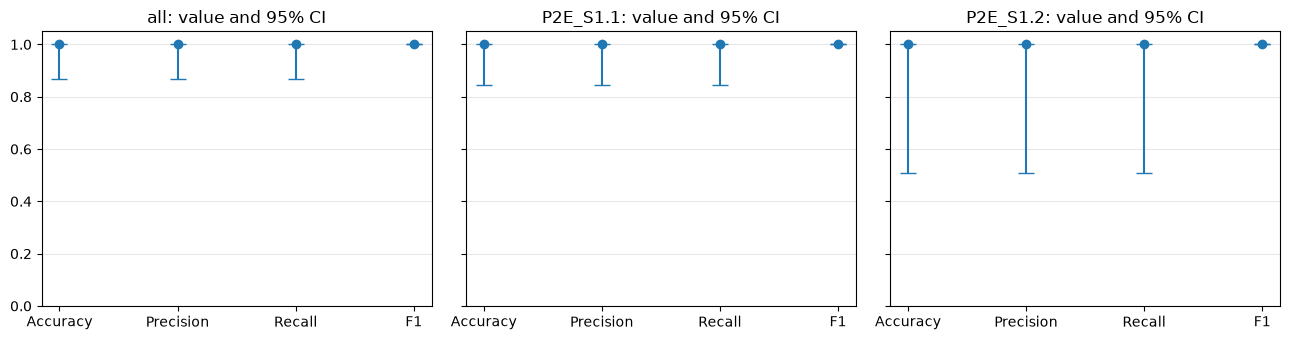

In [7]:
rates = results[results["metric"].isin(["Accuracy", "Precision", "Recall", "F1"])]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, group in zip(axes, ["all", "P2E_S1.1", "P2E_S1.2"]):
    r = rates[rates["group"] == group]
    ax.errorbar(r["metric"], r["value"], yerr=[(r["value"] - r["lower"]).clip(lower=0), (r["upper"] - r["value"]).clip(lower=0)],
                fmt="o", capsize=6)
    ax.set_ylim(0, 1.05)
    ax.set_title(f"{group}: value and 95% CI")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**What the intervals tell us.** All 25 enrolled people are recorded within
0.5 s of when they appear (95% of them within about 0.23 s), so every point estimate is 1.0. With only 25 passes,
the Wilson interval for accuracy is still [0.867, 1.000]: the data are consistent
with an accuracy as low as about 87%. For one recording day (P2E_S1.2, 4 people)
the lower bound drops to about 0.51. More sessions are needed for a narrow interval.
The F1 interval is [1.0, 1.0] because the delta method gives zero width when there
are no errors; read it together with the precision and recall intervals.

## 6. How the settings change the results

Accuracy for thresholds 0.3–0.6 and k 1–10 (tolerance 1 s), and the counts for
tolerances 0.5–5 s with the chosen threshold and k.

In [8]:
def accuracy(threshold, k, tolerance=TOLERANCE):
    out = compare(records_from_predictions(predictions, threshold, k), truth, tolerance)
    return (out["result"] == "match").mean()

grid = pd.DataFrame(
    [{"threshold": th, "k": k, "accuracy": accuracy(th, k)}
     for th in [0.3, 0.4, 0.5, 0.55, 0.6] for k in range(1, 11)]
).pivot(index="threshold", columns="k", values="accuracy")
grid.round(2)

k,1,2,3,4,5,6,7,8,9,10
threshold,,,,,,,,,,
0.30,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
0.40,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
0.50,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
0.55,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.96,0.96,0.96
0.60,0.96,0.96,0.96,0.96,0.96,0.96,0.96,0.96,0.92,0.92


In [9]:
pd.DataFrame([{"tolerance (s)": tol, **count_results(compare(records, truth, tol))}
              for tol in [0.5, 1, 2, 3, 5]])

,tolerance (s),match,late,early,missed,extra
0,0.5,25,0,0,0,0
1,1.0,25,0,0,0,0
2,2.0,25,0,0,0,0
3,3.0,25,0,0,0,0
4,5.0,25,0,0,0,0


Thresholds 0.3–0.5 record everyone; from 0.55 some people are missed.
With threshold 0.5 and k 6, all 25 people match even at the strictest tolerance (0.5 s),
so this setting is used above. No extra records appear in any setting.